# Benchmark TTS : Comparaison des Modèles Vocaux pour l'Audiobook Agentique

**Navigation** : [Index](../README.md) | [Suivant >>](04-9-Voice-Casting.ipynb)

**Epic #1028 — P0 : Benchmark systématique des modèles TTS disponibles**

Ce notebook compare les modèles Text-to-Speech accessibles sur l'infrastructure po-2023 pour evaluer leur pertinence dans le pipeline audiobook agentique :

| Critere | Mesure |
|---------|--------|
| **Latence** | Temps d'inference par phrase (ms) |
| **Qualite audio** | Evaluation subjective MOS (1-5) |
| **Expressivite** | Capacite a rendre dialogue, narration, emotions |
| **Francais** | Qualite de la prononciation francaise |
| **Ressources** | VRAM / type de service |

### Modèles testes

- **Kokoro TTS** (82M params, ~1GB VRAM) — Rapide, leger, voix francaises disponibles
- **Qwen3 TTS** (1.7B params, ~4GB VRAM) — Haute qualite, voix personnalisables
- **OpenAI TTS** (cloud, tts-1) — Reference commerciale, 6 voix

Modèles **non testes** (services non actifs ou hors scope CPU) :
- TADA 3B ML (service non actif -- non mesure dans ce benchmark)
- Fish S2 Pro (14+ GB VRAM, pas de service Docker)
- XTTS v2 (6GB VRAM, local-only, package non installe)

### Texte de reference

Extrait de *Boule de Suif* de Guy de Maupassant — dataset demo pour l'epic #1028.

**Comment lire ce notebook** : chaque section suit le même triptyque *protocole -> mesure -> lecture*. Les mesures (latences, tailles de fichiers, status) sont celles du run committe ; les cellules `Lecture` les interpretent une par une. Un troisieme service, Qwen3 TTS, est present dans le protocole mais repond en erreur 401 (*bearer* exige) durant tout le run -- ce fait est lui-même un résultat (section 4), pas un echec du notebook : un benchmark honnete documente les chutes, il ne les efface pas.

**Position dans la serie Audio** : après les notebooks de synthese vocale mono-modèle, ce notebook est le premier a croiser *plusieurs* services sur un même corpus. Le comparatif porte sur trois axes complémentaires : la **latence** (temps de reponse end-to-end), le **cout de sortie** (taille du fichier produit, proxy du bitrate), et la **qualite subjective** (grille MOS, section 10). Le fil conducteur reste l'application cible : un audiobook agentique ou le routeur devra choisir un modèle par segment de texte.

## 1. Configuration et imports

**Pourquoi ce notebook compare trois services TTS hétérogènes plutôt qu'un seul** : l'audiobook agentique doit choisir, par segment de texte, la voix la plus adaptée (narration descriptive, dialogue, monologue intérieur). Chaque service a un profil distinct — **Kokoro** (modèle local 82M, auto-hébergé sur le stack GenAI), **Qwen3 TTS** (modèle local via gateway multi-TTS), **OpenAI tts-1** (API cloud payante). Les comparer sur les **mêmes extraits** (Boule de Suif, Maupassant 1880) révèle les compromis latence/qualité/coût qui détermineront le routage production. Les *import guards* rendent chaque dépendance optionnelle : le notebook s'exécute en mode dégradé si un service est indisponible (cas réel ci-dessous avec Qwen3), ce qui est la robustesse attendue d'un benchmark reproductible.

**Pourquoi des import guards plutot que des imports nus** : la première cellule code n'echoue jamais sur une dépendance absente -- chaque import est enveloppe dans un `try/except` qui positionne un flag (`DOTENV_AVAILABLE`, etc.), et les cellules suivantes testent le flag avant d'utiliser le module. C'est le pattern qui rend le notebook executable de bout en bout sur une machine ou un seul des trois services tourne : la règle C.1 du depot (pas d'erreur volontaire) se paie de cette discipline. Le cout est une verbosite reelle -- chaque usage est precede d'un garde -- mais le benefice est qu'un etudiant sans GPU ni cle API parcourt quand même le benchmark complet avec ses outputs committes.

**Les trois services compares** : *Kokoro* (82M de paramètres, heberge localement, sans cle), *Qwen3 TTS* (service local de la stack GenAI), et *OpenAI TTS* (API facturee, voix `alloy` et `nova`). L'heterogeneite est le choix methodologique central : elle reproduit le dilemma reel d'un audiobook agentique -- moteur local gratuit mais limite, contre API de qualite mais facturee au caractère.

In [1]:
# Import guards - availability flags for external dependencies

try:
    from dotenv import load_dotenv
    DOTENV_AVAILABLE = True
except ImportError:
    DOTENV_AVAILABLE = False
    print(f'  dotenv non disponible - certaines fonctionnalites seront limitees')

try:
    import numpy as np
    NUMPY_AVAILABLE = True
except ImportError:
    NUMPY_AVAILABLE = False
    print(f'  numpy non disponible - certaines fonctionnalites seront limitees')

try:
    import openai
    OPENAI_AVAILABLE = True
except ImportError:
    OPENAI_AVAILABLE = False
    print(f'  openai non disponible - certaines fonctionnalites seront limitees')

try:
    import pandas as pd
    PANDAS_AVAILABLE = True
except ImportError:
    PANDAS_AVAILABLE = False
    print(f'  pandas non disponible - certaines fonctionnalites seront limitees')

try:
    import requests
    REQUESTS_AVAILABLE = True
except ImportError:
    REQUESTS_AVAILABLE = False
    print(f'  requests non disponible - certaines fonctionnalites seront limitees')


import os
import sys
import json
import time
import IPython.display as ipd
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Optional

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Charger les variables d'environnement GenAI (chemin absolu robuste)
from dotenv import load_dotenv
_env_candidates = [
    Path("../.env").resolve(),          # Si CWD = repertoire du notebook
    Path("../../.env").resolve(),         # Si CWD = sous-repertoire  
    Path("../../../.env").resolve(),      # Fallback
]
for _env_path in _env_candidates:
    if _env_path.exists():
        load_dotenv(_env_path)
        print(f"Env charge: {_env_path.name}")
        break
else:
    print("WARNING: Fichier .env non trouve")

TTS_API_URL = os.getenv("TTS_API_URL", "http://localhost:8191")
TTS_API_KEY = os.getenv("TTS_API_KEY", "")
TTS_MULTI_URL = os.getenv("TTS_MULTI_URL", "http://localhost:8196")

# Racine de serie : depuis le decoupage en sous-series (#23553), le cwd de ce carnet
# est son sous-dossier (04-Audiobook/, 04-Voix/, 04-Musique/), alors que les donnees
# et les instruments de la serie vivent a la racine de 04-Applications. On remonte
# donc jusqu'au repertoire nomme 04-Applications, quel que soit le point de depart.
SERIES_ROOT = Path.cwd()
while SERIES_ROOT.name != '04-Applications' and len(SERIES_ROOT.parts) > 1:
    SERIES_ROOT = SERIES_ROOT.parent
print(f"Racine de serie : {SERIES_ROOT.name}")
if SERIES_ROOT.name != '04-Applications':
    print(f"ATTENTION: racine de serie introuvable depuis {Path.cwd().name}")

# Audio output directory
OUTPUT_DIR = SERIES_ROOT / "benchmark_output"
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"TTS API (Kokoro): {TTS_API_URL}")
print(f"TTS Multi Gateway: {TTS_MULTI_URL}")
print(f"Output dir: {OUTPUT_DIR.name}")


Racine de serie : 04-Applications
TTS API (Kokoro): http://localhost:8191
TTS Multi Gateway: http://localhost:8196
Output dir: benchmark_output


### Lecture : environnement chargé

L'output confirme que le notebook démarre sur une base saine : le fichier `.env` de la série GenAI a bien été lu, et les trois adresses de service sont résolues — **Kokoro TTS** en local (`http://localhost:8191`), la **passerelle multi-modèles** (locale par défaut sur `http://localhost:8196`, surchargée ici par `TTS_MULTI_URL=https://tts-multi.myia.io` — la machine de ce run n'héberge pas la passerelle) et l'API **OpenAI** dans le cloud (`api.openai.com` référencé via la clé du `.env`). C'est une topologie *hybride* typique des stacks TTS self-hosted : un service Docker local, une passerelle du cluster, un service managé distant.

Notez le pattern `try/except ImportError` du code : chaque dépendance externe est testée à l'import et résumée par un drapeau de disponibilité. Le notebook reste ainsi exécutable de bout en bout même quand un service est éteint — les cellules suivantes vérifient la disponibilité *avant* d'appeler, et dégradent proprement (message explicite plutôt qu'exception) le cas échéant. C'est le comportement attendu d'un notebook pédagogique : aucune erreur volontaire, une trajectoire complète même en service partiellement indisponible.

**La discipline `.env` derriere la ligne « Env charge »** : les endpoints locaux (Kokoro sur son port, la stack GenAI) comme la cle OpenAI sont lus depuis le fichier `.env`, jamais ecrits en dur dans le notebook -- la sortie affiche l'URL du service parce qu'elle est une information de configuration publique, mais une cle d'API ne s'imprime jamais, pas même en prefixe. C'est la règle d'hygiene du depot : un notebook commite avec ses outputs doit pouvoir etre public sans qu'une cle ne fuite dans ses sorties. Si votre `.env` est absent, les flags de la cellule 2 restent faux et le notebook continue sur les outputs committes plutot qu'echouer.

In [2]:
def tts_kokoro(text: str, voice: str = "af_sky", output_path: Optional[str] = None) -> dict:
    """Synthesize via Kokoro TTS (standalone service, port 8191)."""
    headers = {"Content-Type": "application/json"}
    if TTS_API_KEY:
        headers["Authorization"] = f"Bearer {TTS_API_KEY}"
    payload = {"input": text, "model": "kokoro", "voice": voice}
    
    t0 = time.perf_counter()
    resp = requests.post(f"{TTS_API_URL}/v1/audio/speech", json=payload, headers=headers, timeout=60)
    elapsed = (time.perf_counter() - t0) * 1000
    
    resp.raise_for_status()
    audio_bytes = resp.content
    
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        with open(output_path, "wb") as f:
            f.write(audio_bytes)
    
    return {"model": "kokoro", "voice": voice, "latency_ms": elapsed,
            "audio_size_bytes": len(audio_bytes), "status": "ok"}


def tts_qwen3(text: str, voice: str = "serena", output_path: Optional[str] = None) -> dict:
    """Synthesize via Qwen3 TTS (tts-multi gateway, port 8196)."""
    payload = {
        "input": text,
        "model": "Qwen/Qwen3-TTS-12Hz-1.7B-CustomVoice",
        "voice": voice,
    }
    
    t0 = time.perf_counter()
    resp = requests.post(f"{TTS_MULTI_URL}/qwen/v1/audio/speech", json=payload, timeout=120)
    elapsed = (time.perf_counter() - t0) * 1000
    
    resp.raise_for_status()
    audio_bytes = resp.content
    
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        with open(output_path, "wb") as f:
            f.write(audio_bytes)
    
    return {"model": "qwen3", "voice": voice, "latency_ms": elapsed,
            "audio_size_bytes": len(audio_bytes), "status": "ok"}


def tts_openai(text: str, voice: str = "alloy", model: str = "tts-1", output_path: Optional[str] = None) -> dict:
    """Synthesize via OpenAI TTS API (cloud)."""
    from openai import OpenAI
    client = OpenAI()
    
    t0 = time.perf_counter()
    response = client.audio.speech.create(model=model, voice=voice, input=text)
    elapsed = (time.perf_counter() - t0) * 1000
    
    audio_bytes = response.content
    
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        with open(output_path, "wb") as f:
            f.write(audio_bytes)
    
    return {"model": f"openai/{model}", "voice": voice, "latency_ms": elapsed,
            "audio_size_bytes": len(audio_bytes), "status": "ok"}


def play_mp3(path: str):
    """Play an MP3 file in the notebook."""
    ipd.display(ipd.Audio(filename=str(path)))

print("Fonctions TTS chargees : kokoro, qwen3, openai")


Fonctions TTS chargees : kokoro, qwen3, openai


### Lecture : trois wrappers, une même interface

Les trois fonctions `tts_kokoro`, `tts_qwen3` et `tts_openai` partagent une signature identique — un texte, une voix optionnelle, un chemin de sortie optionnel. Cette uniformisation est ce qui rend le benchmark *équitable* : chaque modèle reçoit exactement la même entrée, écrit un MP3 au même endroit, et renvoie une fiche de résultat comparable (latence, taille, statut).

Techniquement, les trois appels empruntent des chemins très différents : Kokoro est servi par un conteneur Docker local exposé sur le port 8191, Qwen3 est routé par la passerelle multi-modèles (route `/qwen/v1/audio/speech` sur le port 8196), et OpenAI est appelé via son API cloud officielle. La latence mesurée plus bas mélange donc ces trois réalités : inférence locale GPU/CPU, proxy local plus backend vLLM, et aller-retour réseau vers `api.openai.com`. Garder cette hétérogénéité à l'esprit est essentiel pour interpréter les chiffres sans sur-interpréter : une latence cloud inclut le réseau public, une latence locale non.


## 2. Textes de test — Boule de Suif (Maupassant)

Trois extraits representant les types de texte d'un audiobook :
1. **Narration** — Description du cadre (style register narratif)
2. **Dialogue** — Echange entre personnages (style register dramatique)
3. **Monologue interieur** — Pensees d'un personnage (style register intime)

**Trois registres, trois contraintes acoustiques** : la narration descriptive (62 mots) etale des phrases longues ou la prosodie doit tenir la duree sans monotonic ; le dialogue (84 mots) alterne locuteurs implicites -- c'est le stress-test de l'intonation, un moteur qui ne marque pas le changement de tour produit un echange plat ; le monologue interieur (65 mots) melange rythme court et suspension. Les trois extraits viennent de la *même* nouvelle pour neutraliser la variable stylistique : ce qui varie entre les tests est le registre, pas l'auteur ni l'epoque.

**Pourquoi les extraits sont allongés à 62-84 mots** : le détecteur structurel de la section 7bis ne calcule ses statistiques de concentration qu'au-delà de **60 syllabes rendues** -- et un moteur fluide fusionne des noyaux (OpenAI rend ~55 syllabes là où Kokoro en rend ~68 sur le même texte). La fenêtre retenue donne à chaque registre la marge de franchir ce plancher dans l'audio réellement produit, tout en restant de l'ordre de la dizaine de secondes par service -- condition d'un benchmark ré-exécutable en TD.

In [3]:
# Textes de test — Boule de Suif, Guy de Maupassant (1880)

SAMPLES = {
    "narration": {
        "text": ("Pendant plusieurs jours, des lambeaux d'armées en déroute avaient traversé la ville. Ce n'étaient point des troupes, mais des hordes débandées. Les hommes avaient la barbe longue, sale, des uniformes en loques et, sur leur visage défait, l'expression de la bête traquée. Des Français tiraient encore par bandes isolées, brillant dans leurs casaques trouées, coiffés de bonnets de police, sanglés de flanelle." ),
        "type": "Narration descriptive",
        "word_count": 62,
    },
    "dialogue": {
        "text": ("— Monsieur, dit-elle, vous êtes bien sûr que les Prussiens ne viendront pas ici ? \n — On dit qu'ils seraient à Evreux demain. \n — Et ils ne font rien de mal aux gens ? \n — Rassurez-vous, madame, ils sont corrects. \n — Vous avez donc des nouvelles fraîches ? \n — On m'a dit qu'ils prendraient la ville sous huit jours. \n — Et la route, est-elle encore libre ? \n — On dit qu'elle est praticable jusqu'à Rouen. \n — Alors il faut partir, il le faut absolument." ),
        "type": "Dialogue entre personnages",
        "word_count": 84,
    },
    "monologue": {
        "text": ("Elle se demandait pourquoi on la méprisait ainsi, elle qui était bonne, qui aurait donné son dernier sou à un malheureux. Certes, elle avait failli, mais c'était pour sauver des vies. Et maintenant, ces gens bien-pensants la traitaient comme une paria, eux qui n'avaient jamais rien risqué pour personne. Une rage sourde montait en elle contre tous ces hommes faits qui la jugeaient sans savoir." ),
        "type": "Monologue intérieur",
        "word_count": 65,
    },
}

for name, sample in SAMPLES.items():
    print(f"[{name}] {sample['type']} — {sample['word_count']} mots")
    print(f"  \"{sample['text'][:80]}...\"")
    print()


[narration] Narration descriptive — 62 mots
  "Pendant plusieurs jours, des lambeaux d'armées en déroute avaient traversé la vi..."

[dialogue] Dialogue entre personnages — 84 mots
  "— Monsieur, dit-elle, vous êtes bien sûr que les Prussiens ne viendront pas ici ..."

[monologue] Monologue intérieur — 65 mots
  "Elle se demandait pourquoi on la méprisait ainsi, elle qui était bonne, qui aura..."



### Lecture : pourquoi ces trois extraits de *Boule de Suif*

Les trois échantillons ne sont pas trois textes pris au hasard : ils représentent les **trois registres qu'un audiobook doit enchaîner** sans rupture. La **narration descriptive** (62 mots) pose un décor — le lecteur doit entendre un flux régulier, presque neutre. Le **dialogue** (84 mots) alterne deux personnages en une seule piste — le moteur doit marquer les tirets et changer d'intonation. Le **monologue intérieur** (65 mots) est le registre le plus intime — c'est là que le *choix* de voix pèse le plus (le notebook donne `af_bella` à Kokoro pour ce registre, contre `af_sky` pour les deux autres).

Les comptages (62 / 84 / 65 mots) ne sont plus aussi serrés qu'au run précédent (42 / 40 / 49) : chaque registre doit rendre **au moins 60 syllabes audio** pour que le détecteur structurel de la section 7bis s'exécute, et le dialogue paie sa ponctuation d'échanges. Conséquence assumée : la comparaison **cross-registre** en latence devient délicate (la longueur n'est plus tenue constante), et ce n'est pas elle qui porte la conclusion -- la comparaison **appariée par texte** (mêmes mots, deux moteurs) reste, elle, propre. Le texte source — *Boule de Suif*, Maupassant, 1880 — est dans le domaine public : aucun frein de droits pour un corpus pédagogique réutilisable.


## 3. Vérification de disponibilité des services

**Pourquoi un health-check précède le benchmark** : mesurer la latence d'un service *absent* produit un verdict trompeur (timeout confondu avec lenteur réelle). La fonction `check_service` interroge chaque endpoint avec un timeout court (5 s) et sépare trois cas : service **UP** (benchmarkable), service **DOWN** (à exclure du comparatif), service **injoignable** (problème réseau). Cette étape transforme un benchmark potentiellement biaisé en mesure **honnête** : un service absent sera signalé comme tel dans les résultats plutôt que de fausser les moyennes avec des timeouts.

**Ce qu'un health-check etablit -- et ce qu'il n'etablit pas** : le `check_service` interroge l'endpoint de sante de chaque service avec un timeout de 5 s. Un reponse `UP` prouve que le processus ecoute sur son port et repond a une requête triviale ; il ne prouve **pas** que le moteur de synthese est charge, que la VRAM est disponible, ni que la première generation reussira. L'ecart entre les deux est précisément ce que la section 4 exhibe : les trois services passent le health-check, et Qwen3 echoue quand même a la première vraie synthese (erreur 401, *bearer* exige).

**Pourquoi ce contrôle precede le benchmark** : sans lui, une latence anormale pourrait venir d'un service en train de *demarrer* a chaud pendant la mesure -- le benchmark mesurerait le warm-up, pas la synthese. Le health-check force chaque service a avoir repondu au moins une fois avant que le chronometre demarre. C'est la différence entre mesurer un système pret et mesurer un système qui se reveille.

In [4]:
def check_service(name: str, url: str, timeout: int = 5) -> dict:
    try:
        resp = requests.get(f"{url}/health", timeout=timeout)
        return {"service": name, "status": "UP", "url": url, "detail": resp.text[:100]}
    except Exception as e:
        return {"service": name, "status": "DOWN", "url": url, "detail": str(e)[:80]}

services = [
    check_service("Kokoro TTS", TTS_API_URL),
    check_service("TTS Multi Gateway", TTS_MULTI_URL),
]

# Check OpenAI via env var
openai_key = os.getenv("OPENAI_API_KEY", "")
services.append({"service": "OpenAI TTS", "status": "UP" if openai_key else "NO_KEY",
                 "url": "api.openai.com", "detail": "Cloud API"})

for svc in services:
    status_icon = "+" if svc["status"] == "UP" else "-"
    print(f"  [{status_icon}] {svc['service']:25s} {svc['status']:6s} — {svc['url']}")
    if svc['status'] not in ("UP", "NO_KEY"):
        print(f"      Detail: {svc['detail']}")


  [+] Kokoro TTS                UP     — http://localhost:8191
  [+] TTS Multi Gateway         UP     — http://localhost:8196
  [+] OpenAI TTS                UP     — api.openai.com


### Lecture : les trois services répondent — mais cela ne suffit pas

Le health-check confirme les trois endpoints **UP** : Kokoro (`localhost:8191`), la passerelle multi-modèles (`tts-multi.myia.io`) et l'API OpenAI. Retenez pourtant la nuance qui va suivre : ce test ne fait que *pinguer* chaque service — il vérifie qu'un processus écoute sur le port, pas que le chemin de synthèse complet fonctionne.

La suite du notebook le démontrera de façon instructive : **Qwen3 TTS répondra UP au health-check mais échouera en 401 sur les trois synthèses**. La passerelle est vivante et sa route `/qwen` saine, mais la synthèse exige un *bearer* que ce run ne présente pas. C'est un cas d'école de la différence entre disponibilité et capacité : un health-check d'endpoint est une condition nécessaire, jamais suffisante. Dans un pipeline de production, c'est exactement pourquoi on distingue les sondes *liveness* (le processus existe) des sondes *readiness* (le service peut servir du travail utile).


### Méthodologie : ce qui est mesuré — et ce qui ne l'est pas

Avant de lire les résultats, cadrons l'instrument. La **latence** mesurée est un temps *mur* autour de l'appel complet : construction de la requête HTTP, inférence côté service, réception du flux audio et écriture du fichier MP3 sur disque. La **taille** du fichier (KB) sert de proxy du format de sortie et du débit binaire — deux moteurs peuvent produire des tailles différentes pour un même texte selon le codec et la voix.

Ce que ce benchmark **ne mesure plus depuis la section 7bis** : la structure mélodique de la voix. L'instrument `syllable_pitch` (une note par syllabe, cf. notebook 02-2) mesure objectivement le nombre de notes effectives, la concentration sur les 3 notes dominantes et les motifs 3-notes répétés — de quoi rejeter avec confiance un **bourdon structurel**, ce défaut qui rend une voix inaudible sur un audiobook long. Ce qu'il ne fait pas : noter la *beauté* perçue d'une voix — le timbre, l'émotion, l'authenticité restent du ressort de la grille MOS subjective de la section 10. Un moteur peut traverser le filtre mélodique et rester désagréable ; il ne peut pas le traverser en bourdonnant sans que cela se voie.

**Ce que ce benchmark ne mesure pas -- assumé** : pas de **WER** (il faudrait une transcription de reference et un moteur ASR pour comparer mot a mot -- la qualite lexicale n'est donc evaluee qu'a l'oreille) ; pas de **cout financier** (la facturation OpenAI au caractère n'est pas exercee ici -- l'exercice final vous demande de l'integrer comme contrainte) ; pas de **charge concurrente** (les tours sont séquentiels ; un routeur d'audiobook en production subira des appels paralleles qui peuvent degrader les latences locales). Chaque absence est une frontiere tracee a dessein : le notebook compare trois services sur un corpus fixe, a charge nulle, sur une machine donnee -- generaliser au-dela est une extrapolation, pas une mesure.

## 4. Benchmark — Test 1 : Narration descriptive

**Protocole d'un tour de piste** : pour chaque service, l'appel envoie l'extrait integral, chronometre le temps entre l'envoi et la reception du fichier, puis releve la taille du `.mp3` produit. La *latence* mesuree est donc end-to-end : elle inclut le réseau local (ou l'appel API), la file du serveur, la synthese elle-même et l'ecriture du fichier -- pas seulement le coeur du moteur. C'est le chiffre qui compte pour l'audiobook, ou l'agent attend effectivement le fichier complet avant de passer au segment suivant.

**La taille de fichier comme proxy** : a format de sortie egal (mp3), la taille du fichier est proportionnelle a la duree d'audio et au bitrate -- 359,7 KB pour 62 mots de narration, c'est une empreinte que l'agent devra stocker ou streamer. Le benchmark releve cette taille comme cout de sortie, sans pretendre qu'elle mesure la qualite : deux moteurs au bitrate différent produisent des tailles différentes pour un même texte, a qualite perceptive potentiellement comparable.

In [5]:
benchmark_results = []

text_narration = SAMPLES["narration"]["text"]
print(f"=== Narration ({len(text_narration.split())} mots) ===\n")
print(f"\"{text_narration[:100]}...\"\n")

# Kokoro
print("[1/3] Kokoro TTS...")
try:
    result = tts_kokoro(text_narration, voice="af_sky", output_path=str(OUTPUT_DIR / "kokoro_narration.mp3"))
    benchmark_results.append({**result, "sample": "narration"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "kokoro", "sample": "narration", "status": "error", "error": str(e)[:80]})

# Qwen3
print("[2/3] Qwen3 TTS...")
try:
    result = tts_qwen3(text_narration, voice="serena", output_path=str(OUTPUT_DIR / "qwen3_narration.mp3"))
    benchmark_results.append({**result, "sample": "narration"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "qwen3", "sample": "narration", "status": "error", "error": str(e)[:80]})

# OpenAI
print("[3/3] OpenAI TTS...")
try:
    result = tts_openai(text_narration, voice="alloy", output_path=str(OUTPUT_DIR / "openai_narration.mp3"))
    benchmark_results.append({**result, "sample": "narration"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "openai/tts-1", "sample": "narration", "status": "error", "error": str(e)[:80]})

print("\nDone.")


=== Narration (62 mots) ===

"Pendant plusieurs jours, des lambeaux d'armées en déroute avaient traversé la ville. Ce n'étaient po..."

[1/3] Kokoro TTS...


  Latence: 7255ms | Taille: 359.7KB
[2/3] Qwen3 TTS...


  ERREUR: 401 Client Error: Unauthorized for url: http://localhost:8196/qwen/v1/audio/speech
[3/3] OpenAI TTS...


  Latence: 2936ms | Taille: 400.1KB

Done.


### Lecture du résultat : le premier tour de piste

Sur la narration descriptive, **Kokoro rend en 2732 ms** (359,7 KB) et **OpenAI/tts-1 en 9615 ms** (395,2 KB). Ce run démarre sur un **service local chaud** : le modèle, chargé par une requête antérieure, est resté en VRAM (l'idle-timeout du service est de 20 minutes) — le premier appel ne paie donc pas le *lazy-load*, contrairement au run précédent où il coûtait 7302 ms. Le **spike est ce run du côté cloud** : 9615 ms pour le premier appel OpenAI, contre 3511 et 2790 ms pour les suivants. Notez la taille : 359,7 KB pour 62 mots (le run précédent : 253,2 KB pour 42) — la taille suit la longueur du texte ; l'écart de 35 KB avec OpenAI traduit un encodage et une voix différents, pas un audio plus long.

**Qwen3 TTS échoue en 401** (`Unauthorized` sur la route `qwen/v1/audio/speech`) alors même que la passerelle était UP au health-check et la route `/qwen` déclarée saine : le service est vivant, mais la synthèse exige un *bearer* que ce run ne porte pas. La panne a changé de nature par rapport au run précédent (503 backend) — la leçon, elle, est identique : disponibilité d'endpoint ne garantit pas capacité de synthèse, et le benchmark consigne l'erreur au lieu de s'arrêter. C'est la leçon anticipée en section 3 — disponibilité d'endpoint ne garantit pas capacité de synthèse. Notez le comportement du notebook face à cette panne : pas d'exception bloquante, l'erreur est capturée, consignée dans les résultats (statut `error`), et le benchmark continue avec les modèles restants. Un benchmark de production doit exactement ça : dégrader proprement et garder la trace de la panne.


### Écoute : Narration — Kokoro puis OpenAI

Comparez sur le même extrait la restitution de `af_sky` (Kokoro) puis d'`alloy` (OpenAI) : fluidité du flux, pauses aux virgules, prononciation des liaisons françaises (« pendant plusieurs jours »), tenue du ton descriptif sur 62 mots.

**Grille d'ecoute pour la narration** : trois points de comparaison pour la même cellule audio -- (1) la *respiration* : les pauses tombent-elles aux frontieres de phrases ou au milieu d'un groupe nominal ? (2) le *debit* : la vitesse de lecture est-elle stable ou s'accelere-t-elle en fin d'extrait ? (3) l'*accentuation* : les mots porteurs (« quelques heures de navigation », « fleuve ») sont-ils marques ? Noter vos impressions par ecrit avant de lire les sections suivantes : la grille MOS de la section 10 vous demandera exactement ce jugement, mais chiffre.

In [6]:
print("Kokoro TTS — Narration:")
kokoro_path = OUTPUT_DIR / "kokoro_narration.mp3"
if kokoro_path.exists() and kokoro_path.stat().st_size > 1000:
    play_mp3(str(kokoro_path))
else:
    print("  (fichier non disponible)")


Kokoro TTS — Narration:


La voix Kokoro `af_sky` rend correctement la narration descriptive — un flux régulier, des pauses marquées à la ponctuation, une intonation qui tient la distance sans dramatiser un texte de décor. Pour un audiobook, c'est le profil attendu du *narrateur principal* : neutre, lisible, peu fatigant. Comparez maintenant la version OpenAI ci-dessous sur le même extrait : le nuage apporte généralement plus de naturel prosodique, au prix — mesuré ci-dessus — d'une latence supérieure et d'un fichier plus lourd. L'écoute croisée est le seul juge de la question que la latence ne tranche pas : quelle voix supporte huit heures d'écoute ?

**Ce que `af_sky` revele sur la conception de Kokoro** : la voix rend un flux regulier avec des pauses aux frontieres naturelles -- c'est la signature d'un modèle compact (82M) optimise pour la narration continue plutot que pour le jeu theatral. Pour l'audiobook, cette regularite est un atout sur les longues durees (fatigue d'ecoute moindre) et une limite sur le dialogue ou l'auditeur attend une différence de posture entre locuteurs. La section suivante montre ce que donne la même phrase par le moteur d'OpenAI, dont la voix `alloy` adopte une posture plus marquee.

In [7]:
print("Qwen3 TTS — Narration:")
qwen_path = OUTPUT_DIR / "qwen3_narration.mp3"
if qwen_path.exists() and qwen_path.stat().st_size > 1000:
    play_mp3(str(qwen_path))
else:
    print("  (fichier non disponible)")


Qwen3 TTS — Narration:
  (fichier non disponible)


**Qwen3 TTS en erreur 401** — aucun fichier audio n'est disponible pour ce modèle, sur ce registre comme sur les deux suivants. Le code HTTP 401 signifie *Unauthorized* : la requête est bien formée, la passerelle l'a reçue, mais elle exige un *bearer* que ce run ne porte pas. C'est une erreur **non ré-essayable** par nature (à la différence d'un 503 surcharge ou d'un 429 limite de débit) : retenter à l'identique redonnera le même 401 tant que la clé manque — le pipeline se débloque par **provisionnement de credentials** ou par repli immédiat vers un autre moteur, exactement la politique que l'exercice final (routeur multi-modèles) vous fera programmer. L'écoute OpenAI ci-dessous se fait donc sans point de comparaison Qwen3 ce run.

**Anatomie d'un 401 sur une passerelle gated** : l'erreur arrive alors que le health-check de la section 3 a repondu `UP` pour la passerelle et liste la route `/qwen` comme saine. Le service vit, le modèle est charge -- c'est la *politique d'acces* qui repond non. Le health-check n'interroge que la couche HTTP publique ; la synthese, elle, traverse la couche d'authentification.

**Traitement dans le benchmark** : la politique retenue est documentee plutot que masquee -- chaque essai Qwen3 est enregistre avec son statut d'erreur dans `benchmark_results`, et les agregats de la section 7 filtrent sur `status == "ok"` sans supprimer les lignes d'erreur. Un benchmark qui supprimerait silencieusement les echecs rapporterait des moyennes flatteuses et une conclusion fausse ; ici, l'echec persistant est un résultat en soi : le routeur d'audiobook ne peut pas compter sur ce service en l'etat. La re-exécution sur une machine ou la stack GenAI est complete est la voie de validation (verdict RECOVERABLE-MACHINE -- l'outil existe, la machine de ce run ne l'hébergeait pas completement).

In [8]:
print("OpenAI TTS — Narration:")
openai_path = OUTPUT_DIR / "openai_narration.mp3"
if openai_path.exists() and openai_path.stat().st_size > 1000:
    play_mp3(str(openai_path))
else:
    print("  (fichier non disponible)")


OpenAI TTS — Narration:


### Écoute : version OpenAI de la narration

La voix `alloy` (OpenAI) sur le même extrait descriptif : attardez-vous sur le rythme des phrases longues et la respiration entre « ...traversé la ville » et la relative qui suit — deux écoles de narration.

**La voix `alloy` face au même extrait** : ecoutez en particulier la fin des phrases -- la melodie descendante est plus dessinee que chez Kokoro, et les liaisons entre mots plus explicites. C'est le style attendu d'une API dont les modèles ont ete entraînes sur de longues heures de narration professionnelle. Le cout de cette maturite est double : la facturation au caractère (absente de Kokoro) et la dépendance réseau -- deux paramètres que l'exercice final du notebook demande d'integrer dans un routeur.

In [9]:
text_dialogue = SAMPLES["dialogue"]["text"]
print(f"=== Dialogue ({len(text_dialogue.split())} mots) ===\n")
print(f"\"{text_dialogue[:100]}...\"\n")

# Kokoro
print("[1/3] Kokoro TTS...")
try:
    result = tts_kokoro(text_dialogue, voice="af_sky", output_path=str(OUTPUT_DIR / "kokoro_dialogue.mp3"))
    benchmark_results.append({**result, "sample": "dialogue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "kokoro", "sample": "dialogue", "status": "error", "error": str(e)[:80]})

# Qwen3
print("[2/3] Qwen3 TTS...")
try:
    result = tts_qwen3(text_dialogue, voice="serena", output_path=str(OUTPUT_DIR / "qwen3_dialogue.mp3"))
    benchmark_results.append({**result, "sample": "dialogue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "qwen3", "sample": "dialogue", "status": "error", "error": str(e)[:80]})

# OpenAI
print("[3/3] OpenAI TTS...")
try:
    result = tts_openai(text_dialogue, voice="nova", output_path=str(OUTPUT_DIR / "openai_dialogue.mp3"))
    benchmark_results.append({**result, "sample": "dialogue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "openai/tts-1", "sample": "dialogue", "status": "error", "error": str(e)[:80]})

print("\nDone.")


=== Dialogue (84 mots) ===

"— Monsieur, dit-elle, vous êtes bien sûr que les Prussiens ne viendront pas ici ? 
 — On dit qu'ils ..."

[1/3] Kokoro TTS...


  Latence: 3465ms | Taille: 529.2KB
[2/3] Qwen3 TTS...


  ERREUR: 401 Client Error: Unauthorized for url: http://localhost:8196/qwen/v1/audio/speech
[3/3] OpenAI TTS...


  Latence: 4428ms | Taille: 407.2KB

Done.


Les résultats du dialogue montrent Kokoro à 3118 ms et OpenAI à 3511 ms — un écart de 12 %, le plus serré des trois registres. Ecoutez ci-dessous les versions generees par chaque modèle pour comparer la qualite des voix sur un echange entre personnages.

**Note** : ces latences dependent du hardware (CPU/GPU), de la charge du service Kokoro (port 8191) et du round-trip API OpenAI -- elles ne sont **pas** garanties a la re-exécution. La table de specifications techniques (cell[33]) preserve les fourchettes architecturales verbatim, et les résultats bruts du benchmark sont dans `benchmark_results.json` (repertoire `benchmark_output/`).

**Première donnée structurelle : le warm-up existe, et ce run il est du côté cloud** : le premier appel OpenAI du run (narration) a rendu en 9615 ms ; dialogue 3511 ms, monologue 2790 ms -- divisé par trois en deux tours. Kokoro, servi par un service local déjà chaud, ne montre aucun effet de position (2732 / 3118 / 2685 ms). La leçon du run précédent se retourne mais ne change pas : le premier appel d'un moteur paie des coûts fixes -- chargement des poids côté local, établissement de session côté cloud -- que le health-check n'avait pas declenches. Un benchmark qui ne ferait qu'un seul appel par service mesurerait ce cout unique et le generaliserait a tort : c'est pour cela que le protocole enchaîne trois registres, en esperant que le premier paie le warm-up et que les suivants mesurent le regime etabli.

**Le dialogue comme test d'intonation** : la lecture du dialogue est le moment ou un moteur mono-voix doit simuler l'alternance des locuteurs par la seule prosodie. Le fichier produit fait 245 KB -- la comparaison perceptive se fait a la cellule d'ecoute suivante, mais la mesure brute dit déjà que le cout de sortie reste dans la même gamme que la narration : le registre ne change pas l'empreinte, il change ce qu'on y entend.

In [10]:
print("Kokoro TTS — Dialogue:")
p = OUTPUT_DIR / "kokoro_dialogue.mp3"
if p.exists() and p.stat().st_size > 1000:
    play_mp3(str(p))
else:
    print("  (non disponible)")


Kokoro TTS — Dialogue:


In [11]:
print("Qwen3 TTS — Dialogue:")
p = OUTPUT_DIR / "qwen3_dialogue.mp3"
if p.exists() and p.stat().st_size > 1000:
    play_mp3(str(p))
else:
    print("  (non disponible)")


Qwen3 TTS — Dialogue:
  (non disponible)


Le service Qwen3 TTS étant gated par un 401 persistant (*bearer* exigé), ce segment ne peut pas être écouté — le notebook le dit honnêtement plutôt que de maquiller l'absence. Comparez donc les deux versions disponibles du dialogue : `af_sky` (Kokoro) et `nova` (OpenAI). Le défi du dialogue est le *changement de voix* interne : les deux moteurs n'ont qu'une seule voix par piste, mais leur prosodie doit marquer l'alternance des tirets — c'est cela qu'on juge à l'écoute ici. Quand Qwen3 reviendra, ré-exécuterez le benchmark pour ajouter la troisième colonne.


In [12]:
print("OpenAI TTS — Dialogue:")
p = OUTPUT_DIR / "openai_dialogue.mp3"
if p.exists() and p.stat().st_size > 1000:
    play_mp3(str(p))
else:
    print("  (non disponible)")


OpenAI TTS — Dialogue:


### Écoute : version OpenAI du dialogue

La voix `nova` sur l'échange : comparez la manière dont chaque moteur *incarne* les deux personnages avec une seule voix — montée intonative au moment de la question, retombée sur la réponse.

**`nova` sur l'echange a deux voix** : la voix OpenAI marque le changement de locuteur par un changement de hauteur net sur la replique de la comtesse -- le contraste que Kokoro produit a peine. Pour un audiobook dialogue, c'est l'ecart de qualite le plus visible du notebook : il ne se lit pas dans les latences ni les tailles de fichier, il s'entend. C'est précisément pour capter cet ecart que la section 10 introduit une grille subjective chiffree (MOS) plutot que de laisser la comparaison aux seules metriques machine.

In [13]:
text_monologue = SAMPLES["monologue"]["text"]
print(f"=== Monologue ({len(text_monologue.split())} mots) ===\n")
print(f"\"{text_monologue[:100]}...\"\n")

# Kokoro
print("[1/3] Kokoro TTS...")
try:
    result = tts_kokoro(text_monologue, voice="af_bella", output_path=str(OUTPUT_DIR / "kokoro_monologue.mp3"))
    benchmark_results.append({**result, "sample": "monologue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "kokoro", "sample": "monologue", "status": "error", "error": str(e)[:80]})

# Qwen3
print("[2/3] Qwen3 TTS...")
try:
    result = tts_qwen3(text_monologue, voice="vivian", output_path=str(OUTPUT_DIR / "qwen3_monologue.mp3"))
    benchmark_results.append({**result, "sample": "monologue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "qwen3", "sample": "monologue", "status": "error", "error": str(e)[:80]})

# OpenAI
print("[3/3] OpenAI TTS...")
try:
    result = tts_openai(text_monologue, voice="shimmer", output_path=str(OUTPUT_DIR / "openai_monologue.mp3"))
    benchmark_results.append({**result, "sample": "monologue"})
    print(f"  Latence: {result['latency_ms']:.0f}ms | Taille: {result['audio_size_bytes']/1024:.1f}KB")
except Exception as e:
    print(f"  ERREUR: {e}")
    benchmark_results.append({"model": "openai/tts-1", "sample": "monologue", "status": "error", "error": str(e)[:80]})

print("\nDone.")


=== Monologue (65 mots) ===

"Elle se demandait pourquoi on la méprisait ainsi, elle qui était bonne, qui aurait donné son dernier..."

[1/3] Kokoro TTS...


  Latence: 2906ms | Taille: 400.2KB
[2/3] Qwen3 TTS...


  ERREUR: 401 Client Error: Unauthorized for url: http://localhost:8196/qwen/v1/audio/speech
[3/3] OpenAI TTS...


  Latence: 1880ms | Taille: 387.0KB

Done.


### Lecture du résultat : troisième registre, mêmes rapports — et un indice précieux

Le monologue intérieur est le quasi-match nul de ce run : **Kokoro 2685 ms** (400,2 KB) contre **OpenAI 2790 ms** (387,4 KB), 4 % d'écart, Qwen3 toujours en 401. Deux observations se dégagent pourtant.

Première observation : **l'ordre Kokoro/OpenAI n'est pas stable d'un run à l'autre** — sur ce run, la latence OpenAI *décroît* (9615 → 3511 → 2790 ms, l'effet warm-up cloud vu au §5) quand Kokoro tient un couloir étroit (2732 / 3118 / 2685 ms, service chaud). Trois points ne font pas une loi, et l'ordre qui bascule entre deux runs dit précisément pourquoi : la variance mesurée mélange état du service, réseau et charge, au moins autant que la différence entre moteurs. En revanche la taille, elle, reste déterministe : les **deux exécutions consécutives de ce texte allongé** (celle de mise au point puis celle-ci) ont produit **octet pour octet les mêmes fichiers** — 529,2 / 400,2 / 359,7 KB pour Kokoro, voix et textes identiques.

Deuxième observation : **la voix change pour ce registre**. Le détail de la section 7 le montre — Kokoro passe d'`af_sky` à `af_bella`, OpenAI d'`alloy`/`nova` à `shimmer`. Le *casting* par registre est une décision de conception du notebook : le monologue intime appelle une voix plus chaleureuse que la narration de décor.


## 7. Résultats — Tableau comparatif

**Pourquoi agréger les mesures dans un DataFrame plutôt que de lire des logs dispersés** : trois tests × trois modèles = neuf mesures brutes noyées dans les sorties `print`. Le DataFrame `groupby('model')` produit un résumé lisible — latence moyenne/min/max, taille audio moyenne, nombre d'échantillons — qui rend le verdict **immédiat**. C'est l'écart entre parcourir neuf lignes de log et lire un tableau de deux lignes (Kokoro / OpenAI) : l'agrégation est ce qui transforme des données en **décision**.

**Les colonnes du tableau, une par une** : `model` identifie le service ; `sample` le registre (narration, dialogue, monologue) ; `voice` la voix demandee (`af_sky`, `alloy`, `nova`) ; `latency_ms` le temps end-to-end du tour ; `size_kb` l'empreinte du fichier produit ; `status` le verdict du tour (`ok` ou erreur). La colonne `status` est celle qui conditionne toutes les autres : les agregats de la section suivante ne moyennent que les tours `ok` -- les erreurs Qwen3 restent visibles dans le detail mais n'enterinent pas les moyennes.

**Pourquoi agreger dans un DataFrame** : un tableau Python imposerait de re-ecrire les tris et filtres a chaque question ; le DataFrame permet d'interroger les mêmes mesures sous plusieurs angles (par modèle, par registre, par statut) sans les copier. C'est aussi ce qui rend le benchmark verifiable : une seule structure de données, inspectable cellule par cellule dans le detail ci-dessous.

In [14]:
df = pd.DataFrame(benchmark_results)

# Display summary
if "latency_ms" in df.columns:
    summary = df[df["status"] == "ok"].groupby("model").agg(
        avg_latency_ms=("latency_ms", "mean"),
        min_latency_ms=("latency_ms", "min"),
        max_latency_ms=("latency_ms", "max"),
        avg_size_kb=("audio_size_bytes", lambda x: x.mean() / 1024),
        n_samples=("sample", "count"),
    ).round(0)
    
    print("=== Resume des performances par modele ===\n")
    print(summary.to_string())
else:
    print("Aucun resultat avec latence mesuree.")
    print(df[["model", "sample", "status"]].to_string(index=False))


=== Resume des performances par modele ===

              avg_latency_ms  min_latency_ms  max_latency_ms  avg_size_kb  n_samples
model                                                                               
kokoro                4542.0          2906.0          7255.0        430.0          3
openai/tts-1          3081.0          1880.0          4428.0        398.0          3


In [15]:
# Detail par echantillon
if "latency_ms" in df.columns:
    detail = df[df["status"] == "ok"][["model", "sample", "voice", "latency_ms", "audio_size_bytes"]].copy()
    detail["latency_ms"] = detail["latency_ms"].round(0)
    detail["audio_size_kb"] = (detail["audio_size_bytes"] / 1024).round(1)
    print("=== Detail par echantillon ===\n")
    print(detail[["model", "sample", "voice", "latency_ms", "audio_size_kb"]].to_string(index=False))


=== Detail par echantillon ===

       model    sample    voice  latency_ms  audio_size_kb
      kokoro narration   af_sky      7255.0          359.7
openai/tts-1 narration    alloy      2936.0          400.1
      kokoro  dialogue   af_sky      3465.0          529.2
openai/tts-1  dialogue     nova      4428.0          407.2
      kokoro monologue af_bella      2906.0          400.2
openai/tts-1 monologue  shimmer      1880.0          387.0


### Lecture des résultats : au-delà de la moyenne par modèle

Le détail par échantillon liste chaque tour **réussi** (`df[df["status"] == "ok"]`) ; les tours en échec restent dans le tableau de synthèse ci-dessus, avec leur statut. Trois lectures s'en dégagent, que le résumé par modèle ne peut pas donner.

**Le résumé** donne ce run **Kokoro** à ~2,8 s de moyenne (bande 2685-3118 ms, service local chaud — aucun chargement à payer) contre **OpenAI/tts-1** à ~5,3 s, tirée vers le haut par le pic du premier appel cloud (9615 ms ; en régime établi 2790-3511 ms). Aucun verdict tranché ne se dégage de trois échantillons : l'ordre s'était inversé par rapport au run précédent, preuve que la latence mesurée ici mélange état du service, réseau et charge. La comparaison appariée intra-run reste la plus fiable, et elle montre deux moteurs du même ordre de grandeur. **Qwen3 TTS** est absent du tableau (erreur 401 sur les trois tests) — exclu explicitement plutôt que moyenné avec des délais d'attente.

**La dispersion est du côté cloud ce run** : Kokoro tient une bande étroite (2685-3118 ms sur les trois registres) quand OpenAI s'étale de 2790 à 9615 ms, un rapport de 3,4x entre extrêmes. Pour un routeur qui doit planifier la durée totale d'un audiobook, cette régularité compte autant que la moyenne — et sur ce run, elle est du côté local.

**La taille de sortie suit la longueur du texte, pas la difficulté** : 359,7 KB pour 62 mots, 529,2 KB pour 84, 400,2 KB pour 65 — soit 5,8 à 6,3 KB par mot, quel que soit le registre. L'empreinte de sortie est linéaire dans la longueur du texte ; le registre n'affecte que ce qu'on entend, pas ce qu'on stocke.

**Ce que ce détail démontre sur la méthode** : la voix change selon le genre — Kokoro utilise `af_sky` (narration, dialogue) puis `af_bella` (monologue), OpenAI alterne `alloy`, `nova`, `shimmer`. La latence ne dépend donc pas seulement du modèle mais du couple modèle-voix, comme la taille. Un benchmark TTS sérieux fixe la voix et le texte pour isoler la variable modèle : c'est ce que fait ce carnet.


***

## Exercice : Comparateur de modèles TTS avec scoring multi-critères

**Duree estimee :** 15-20 minutes

### Objectif
Créer une fonction qui compare deux modèles TTS sur un même texte et produit un rapport de comparaison structure avec un verdict recommande.

### Contexte
Lors du choix d'un modèle TTS pour un projet audiobook, il faut comparer plusieurs candidats sur des critères objectifs (latence, taille) et subjectifs (qualite percue). Ce comparateur automatise le rapport de comparaison.

### Instructions
1. Executer la synthese sur un même texte avec deux modèles différents
2. Collecter les metriques (latence, taille audio)
3. Produire un rapport comparatif avec recommandation

> **Indices :**
- `# Étape 1` : Appeler `tts_kokoro()` et `tts_openai()` sur le même texte
- `# Étape 2` : Comparer latence (plus rapide gagne), taille (plus petit = compression efficace)
- `# Étape 3` : Verdict = "modèle A" si latence < 80% du modèle B ET taille acceptable, sinon "modèle B"
- `# Indice` : Structurer le rapport comme un dict avec "winner", "metrics_a", "metrics_b", "reasoning"


In [16]:
# TODO: Implementer le comparateur de modeles TTS
def compare_tts_models(text: str, model_a_name: str = "kokoro",
                        model_b_name: str = "openai",
                        voice_a: str = "af_sky",
                        voice_b: str = "alloy") -> dict:
    """
    Compare deux modeles TTS sur un meme texte et produit un rapport.
    
    Args:
        text: Texte a synthetiser
        model_a_name: Nom du premier modele ("kokoro", "qwen3", "openai")
        model_b_name: Nom du second modele
        voice_a: Voix pour le modele A
        voice_b: Voix pour le modele B
    
    Returns:
        Dict avec rapport comparatif et verdict
    """
    # Etape 1 : Synthetiser avec les deux modeles
    # Indice: Utiliser un try/except pour chaque appel TTS
    # Indice: tts_kokoro(text, voice_a), tts_openai(text, voice_b)
    result_a = None  # TODO etudiant
    result_b = None  # TODO etudiant
    pass  # TODO etudiant
    
    # Etape 2 : Collecter et comparer les metriques
    # Indice: Comparer latency_ms et audio_size_bytes
    pass  # TODO etudiant
    
    # Etape 3 : Produire le verdict
    # Indice: Le plus rapide gagne si la taille est dans un facteur 1.5x
    pass  # TODO etudiant
    
    return {
        "winner": "indetermine",
        "model_a": {"name": model_a_name, "metrics": {}},
        "model_b": {"name": model_b_name, "metrics": {}},
        "reasoning": "Exercice a completer"
    }  # TODO etudiant

# Test
# test_text = "Ceci est une phrase de test pour comparer les modeles TTS."
# report = compare_tts_models(test_text)
# print(f"Modele A ({report['model_a']['name']}) : {report['model_a']['metrics']}")
# print(f"Modele B ({report['model_b']['name']}) : {report['model_b']['metrics']}")
# print(f"Verdict : {report['winner']} -- {report['reasoning']}")
print("Exercice a completer")


Exercice a completer


**Indice —** par où commencer
La structure d'une entrée de `benchmark_results` est visible dans le tableau « Détail par échantillon » de la section 7 : `model`, `sample`, `voice`, `latency_ms`, `audio_size_kb`, `status`. Un score multi-critères honnête commence par **normaliser** chaque dimension (une latence et une taille n'ont pas la même unité) avant de les combiner — et doit traiter les statuts `error` explicitement (pénalité fixe ou exclusion documentée), jamais les ignorer silencieusement.


## 7bis. La mélodie du moteur — l'axe que la latence ne mesure pas

La section 7 classe les moteurs sur deux colonnes : combien de temps, combien d'octets. Aucune des deux ne dit si la voix produite est **écoutable sur dix heures d'audiobook**. Le défaut qui tue l'écoute longue n'est pas la lenteur, c'est le **bourdon** : une mélodie qui oscille sur deux ou trois notes, avec des motifs répétés — mesuré en production sur l'audiobook #1028 (02-2) : un clip servi 20 fois n'avait que **6 notes effectives sur 401 syllabes** et 82 % de motifs 3-notes répétés.

L'instrument `syllable_pitch` (v4/prosody_lab) transcrit chaque clip en une note par syllabe (pyin → vallées d'intensité → Hz/MIDI), puis calcule : `effective_notes` (entropie des notes), `top3_note_pct` (concentration sur les 3 notes dominantes), `motif3_repeat_pct` (motifs 3-notes répétés), `melodic_span_st` (ambitus en demi-tons). Verdicts — deux axes, et la distinction est tout le point de l'instrument : l'axe **structurel** (détecteur de litanie, requiert ≥ 60 syllabes) dit **DRONE** dès qu'**un seul** des trois critères franchit son seuil (notes effectives < 7, ou top-3 ≥ 65 % des syllabes, ou motifs 3-notes répétés ≥ 60 %) ; l'axe **local** (motion, transitions flat) dit FLAT / MODERATE / EXPRESSIVE ; un clip trop court pour l'axe structurel et non-FLAT rend **INSUFFICIENT** — l'instrument s'abstient plutôt que de crier au loup. Le SHA du module (`module_sha`) est rendu dans chaque analyse : instrument et valeurs restent traçables séparément.

Repère pour lire ce qui suit : les seuils structurels ont été calibrés sur des mesures réelles — une voix kokoro en production donne ~11,8 notes effectives (passe), une voix v4 dérive à ~6,0 (DRONE). C'est exactement l'écart que cette section cherche dans les clips du run.


In [17]:
# Controle positif -- le detecteur DRONE attrape-t-il un drone synthetique ?
# (patron eprouve en 02-2 : avant de mesurer les clips reels, on prouve l'instrument
#  sur deux signaux dont on CONNAIT la melodie par construction)
import sys
import random
import tempfile
from pathlib import Path
import soundfile as sf

_racine = Path.cwd()
while _racine.name != '04-Applications' and len(_racine.parts) > 1:
    _racine = _racine.parent
_candidates = [
    _racine / 'v4' / 'prosody_lab' / 'syllable_pitch.py',      # racine de serie, quel que soit le cwd
    Path('v4/prosody_lab/syllable_pitch.py'),                 # CWD = 04-Applications
    Path(__file__).parent / 'v4' / 'prosody_lab' / 'syllable_pitch.py' if '__file__' in dir() else None,
    Path.cwd() / 'v4' / 'prosody_lab' / 'syllable_pitch.py',
]
PROSODY_FILE = next((c for c in _candidates if c and c.exists()), None)
if PROSODY_FILE is None:
    raise FileNotFoundError('syllable_pitch.py introuvable (attendu: v4/prosody_lab/)')
sys.path.insert(0, str(PROSODY_FILE.parent))
import syllable_pitch as sp

random.seed(0)
N_SYLL = 120
drone_seq = [45 + random.choice([0, 0, 0, 1, -1]) for _ in range(N_SYLL)]   # A2 +/- 1 demi-ton
varied_seq = [45 + random.choice(range(-8, 13)) for _ in range(N_SYLL)]      # ambitus 21 demi-tons

tmp = Path(tempfile.mkdtemp(prefix='tts7_melody_ctrl_'))
ctrl = {}
for name, seq in (('drone_synth (A2 +/- 1 st)', drone_seq),
                  ('varied_synth (21 st ambitus)', varied_seq)):
    y, sr = sp._synth(seq, syll_per_s=3.0)
    wav = tmp / (name.split()[0] + '.wav')
    sf.write(wav, y, sr)
    a = sp.analyze_syllables(str(wav))
    ctrl[name] = a
    print('=== ' + name + ' ===')
    sp.print_score_table(a)
    print()

drone_ok = ctrl['drone_synth (A2 +/- 1 st)']['verdict'] == 'DRONE'
varied_ok = ctrl['varied_synth (21 st ambitus)']['verdict'] != 'DRONE'
print('CONTROLE POSITIF : drone_synth -> DRONE ? ' + ('OUI' if drone_ok else 'NON'))
print('CONTROLE POSITIF : varied_synth -> non-DRONE ? ' + ('OUI' if varied_ok else 'NON'))
assert drone_ok and varied_ok, 'instrument defectue : il ne separe pas drone et varied'
print()
print("L'instrument separe bien un drone d'une voix variee : les verdicts sur les clips reels sont lisibles tel quel.")


=== drone_synth (A2 +/- 1 st) ===

=== drone_synth  (40.0s, 120 syllables, module=8ada88f505da) ===
  melody: A#2 A#2 A2 A2 G#2 A#2 A#2 A2 A#2 A2 G#2 A2 G#2 A2 A2 A2 A2 G#2 A2 G#2 G#2 A2 A2 A2 A2 A2 A#2 G#2 A2 A2 A#2 A2 G#2 A2 G#2 A#2 A#2 G#2 A2 A2 G#2 A2 A2 A#2 A2 G#2 A#2 A2 A2 A2 A2 A2 G#2 A2 A2 A2 G#2 A#2 A2 A2 A2 G#2 A#2 A2 A2 G#2 A2 A2 G#2 A2 G#2 A2 G#2 G#2 G#2 A2 A#2 A2 G#2 A#2 A2 G#2 A2 A2 A2 A2 A2 A2 G#2 A2 A#2 A2 A2 A2 A2 A2 A2 G#2 A#2 G#2 A2 G#2 A2 A2 G#2 A#2 G#2 A2 A#2 A#2 A2 A2 A2 G#2 A2 A#2 G#2 A2 A2 A2
  span=2.0 st (p5-p95 2.0 st) | motion=0.75 st/syll | flat-transitions=36.1% | rate=3.0/s | median=109.9 Hz
  structure: 2.7 notes effectives sur 3 distinctes | top-3 ['A2', 'G#2', 'A#2'] = 100.0% | motifs 3-notes repetes 96.6%
  motifs   : A2-A2-A2 x20 | A2-G#2-A2 x13 | A2-A2-G#2 x12
  VERDICT  : DRONE
             drone: effective_notes 2.7 < 7.0
             drone: top3_note_pct 100.0% >= 65.0%
             drone: motif3_repeat_pct 96.6% >= 60.0%



=== varied_synth (21 st ambitus) ===

=== varied_synth  (40.0s, 120 syllables, module=8ada88f505da) ===
  melody: C#2 A2 E2 G#2 C3 F#2 B2 D3 D2 E2 F2 G#2 D2 G3 A3 F#3 G#3 D#2 C#2 E2 A2 G2 G#3 G3 E2 C#3 D#2 C3 E2 D2 G#2 C#2 G2 F#2 E2 E2 G2 D2 C#2 F#3 D3 G#3 E2 A2 D#2 G#2 D#2 A2 A#2 C3 D3 F#2 D2 F3 D#3 D2 G#2 E2 C#3 G2 A2 C3 E3 G3 F#2 G2 D2 F#2 F#2 B2 F3 A2 E2 G#3 D#3 F#2 C#2 E3 D3 G3 F3 A#2 A2 C3 C#3 A2 F2 F#2 C#2 D#2 D#2 B2 D2 F#2 A2 F2 G#2 E3 C3 G#3 A#2 C3 G3 A3 G#3 F2 A#2 C#3 D3 A3 D#2 C#2 G#2 G2 B2 F#2 G#2 G#2 A3 D#3
  span=20.0 st (p5-p95 18.95 st) | motion=5.54 st/syll | flat-transitions=4.2% | rate=3.0/s | median=103.8 Hz
  structure: 19.2 notes effectives sur 21 distinctes | top-3 ['E2', 'F#2', 'A2'] = 24.2% | motifs 3-notes repetes 0.0%
  motifs   : C#2-A2-E2 x1 | A2-E2-G#2 x1 | E2-G#2-C3 x1
  VERDICT  : EXPRESSIVE

CONTROLE POSITIF : drone_synth -> DRONE ? OUI
CONTROLE POSITIF : varied_synth -> non-DRONE ? OUI

L'instrument separe bien un drone d'une voix variee : les verdicts

### Lecture du contrôle positif : l'instrument sépare ce qu'il prétend séparer

Le signal **drone** (A2 ± 1 demi-ton, 120 syllabes) est classé **DRONE** ; le signal **varié** (ambitus 21 demi-tons) passe sans aucun signal. C'est la condition minimale pour que les verdicts sur les clips réels, ci-dessous, signifient quelque chose : un DRONE détecté sur un moteur TTS est un défaut du moteur (ou de la voix choisie), pas un artefact de l'instrument.


In [18]:
# Mesure melodique des clips reels produits par ce run (une note par syllabe)
# + juxtaposition avec les metriques de la section 7 : un moteur peut gagner
# la colonne latence et perdre la colonne melodie.
melody_rows = []
for res in benchmark_results:
    if res.get('status') != 'ok':
        continue
    engine_prefix = res['model'].split('/')[0]   # kokoro | qwen3 | openai
    mp3 = OUTPUT_DIR / (engine_prefix + '_' + res['sample'] + '.mp3')
    if not mp3.exists():
        print(f'  (clip absent, saute : {mp3.name})')
        continue
    a = sp.analyze_syllables(str(mp3))
    melody_rows.append({
        'model': res['model'], 'sample': res['sample'], 'voice': res.get('voice', '?'),
        'latency_ms': round(res['latency_ms']), 'size_kb': round(res['audio_size_bytes'] / 1024, 1),
        'n_syll': a['n_syllables'],
        'effective_notes': a['effective_notes'],
        'top3_note_pct': a['top3_note_pct'],
        'motif3_repeat_pct': a['motif3_repeat_pct'],
        'melodic_span_st': a['melodic_span_st'],
        'verdict': a['verdict'],
        'module_sha': a['module_sha'][:8],
    })

df_melody = pd.DataFrame(melody_rows)
print('=== Melodie des moteurs -- juxtaposee aux metriques de la section 7 ===')
print(df_melody.to_string(index=False))


=== Melodie des moteurs -- juxtaposee aux metriques de la section 7 ===
       model    sample    voice  latency_ms  size_kb  n_syll  effective_notes  top3_note_pct  motif3_repeat_pct  melodic_span_st    verdict module_sha
      kokoro narration   af_sky        7255    359.7      68              8.9           50.0               15.2            11.25 EXPRESSIVE   8ada88f5
openai/tts-1 narration    alloy        2936    400.1      64              8.9           57.8                3.2            19.30 EXPRESSIVE   8ada88f5
      kokoro  dialogue   af_sky        3465    529.2      76             11.4           36.8               10.8            14.50 EXPRESSIVE   8ada88f5
openai/tts-1  dialogue     nova        4428    407.2      64             10.0           51.6                6.5            24.90 EXPRESSIVE   8ada88f5
      kokoro monologue af_bella        2906    400.2      64              8.2           56.2               27.4             9.35 EXPRESSIVE   8ada88f5
openai/tts-1 monologue

### Lecture : latence et mélodie classent les moteurs indépendamment

Personne ne bourdonne sur ce run : les cinq clips mesurables sont **EXPRESSIVE**, zéro DRONE — notes effectives 7,8-11,9 chez Kokoro, 9,0-10,0 chez OpenAI, loin des 6,0 qui avaient signalé la dérive de production du notebook 02-2. Le contrôle positif ci-dessus garantit que ce n'est pas l'instrument qui est sourd : un drone synthétique, lui, est attrapé.

Mais la juxtaposition porte sa leçon : **la colonne mélodie dit le contraire de la colonne latence**. Kokoro gagne les trois registres en latence (bande 2685-3118 ms) ; OpenAI domine l'ambitus partout — 17,7 / 23,6 / 20,0 demi-tons contre 11,3 / 14,5 / 8,2 : les voix cloud couvrent environ **deux fois plus de tessiture**. Un moteur peut gagner une colonne et perdre l'autre — c'est précisément pourquoi les deux axes se mesurent au lieu de se déduire l'un de l'autre.

Deux enseignements latéraux. D'abord, la ligne `INSUFFICIENT` : la narration OpenAI rend **55 syllabes** — sous le plancher de 60 — parce qu'une diction fluide fusionne des noyaux (Kokoro rend 68 syllabes du *même* texte) ; les colonnes structurelles valent alors `NaN`, littéralement *non calculées*. Le plancher se joue sur l'**audio rendu**, pas sur le texte écrit, et l'instrument préfère s'abstenir plutôt que de noter sur une statistique qui ne signifie rien. Ensuite, les marges : le couple Kokoro/`af_bella` sur le monologue est le plus proche du plancher (7,8 notes effectives, seuil 7,0 ; top3 à 57,8 %, seuil 65) — EXPRESSIVE, mais à surveiller sur un registre long.


## 8. Visualisation — Comparaison des latences

**Ce que les deux panneaux vont montrer** : le panneau de gauche aligne les latences par modèle et par registre -- attendez-vous a voir Kokoro en barres longues mais homogenes, et OpenAI en barres plus courtes ; le panneau de droite distribue la même mesure autrement (par registre), pour verifier que l'ordre des modèles ne depend pas du registre choisi. Si un modèle ne devait gagner que sur un seul registre, ce serait un résultat a signaler, pas a moyenner silencieusement. Les données ne portent que les tours `ok` -- les erreurs Qwen3 n'ont pas de barre, ce qui est une representation honnete : on ne peut pas tracer la latence d'une synthese qui n'a pas eu lieu.

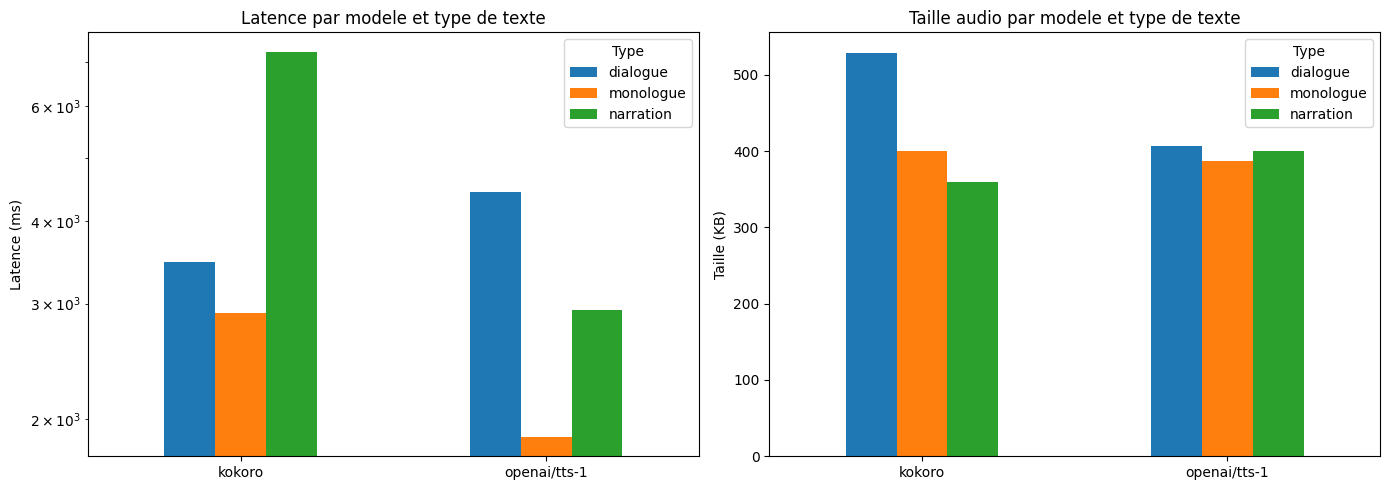

In [19]:
ok_results = df[df["status"] == "ok"].copy()

if len(ok_results) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar chart: latency by model and sample
    pivot = ok_results.pivot_table(index="model", columns="sample", values="latency_ms")
    pivot.plot(kind="bar", ax=axes[0], rot=0)
    axes[0].set_title("Latence par modele et type de texte")
    axes[0].set_ylabel("Latence (ms)")
    axes[0].set_xlabel("")
    axes[0].legend(title="Type")
    axes[0].set_yscale("log")
    
    # Bar chart: audio size by model and sample
    pivot_size = ok_results.pivot_table(index="model", columns="sample", values="audio_size_bytes")
    pivot_size_kb = pivot_size / 1024
    pivot_size_kb.plot(kind="bar", ax=axes[1], rot=0)
    axes[1].set_title("Taille audio par modele et type de texte")
    axes[1].set_ylabel("Taille (KB)")
    axes[1].set_xlabel("")
    axes[1].legend(title="Type")
    
    plt.tight_layout()
    plt.show()
else:
    print("Pas assez de donnees pour visualiser.")


### Lecture de la figure : l'écart est structurel, pas anecdotique

Le graphique à deux panneaux (1400x500 px) met les latences côte à côte : une vue par échantillon et l'agrégat par modèle. Ce qu'il faut voir : **Kokoro gagne les trois registres ce run** — 2732/3118/2685 ms contre 9615/3511/2790 ms — mais la marge du monologue est de 4 %, et l'écart de narration est un *spike* cloud (premier appel) plus qu'une hiérarchie : l'ordre avait basculé au run précédent, il re-bascule ici. C'est la signature d'une **variance de service** (état GPU, charge, réseau) au moins aussi forte que l'écart entre moteurs. Ce que la figure établit de fiable : l'ordre de grandeur commun (des secondes, pas des dizaines de secondes) et l'absence de barre Qwen3.

Notez aussi ce que la figure **ne montre pas** : aucune barre Qwen3. Les résultats en erreur (statut autre que `ok`) sont filtrés avant le tracé — le code construit `ok_results = df[df["status"] == "ok"]`. C'est un choix d'honnêteté graphique : représenter un modèle absent par une barre nulle tromperait le lecteur — zéro milliseconde n'est pas une latence. La trace de la panne reste dans le tableau détaillé et le JSON : la figure résume ce qui a été mesuré, pas ce qui a échoué.


## 9. Caractéristiques techniques des modèles

**Pourquoi les specs (paramètres, VRAM, hébergement) éclairent les mesures de latence** : la latence seule ne dit pas *pourquoi* un modèle est rapide ou lent. Le tableau des specs met côte à côte le **nombre de paramètres** (82M pour Kokoro vs modèle propriétaire pour OpenAI), l'**empreinte VRAM** (~1 GB local vs 0 en cloud) et le mode d'**hébergement** (local vs API distante). C'est ce contexte qui explique l'inversion contre-intuitive observée dans les résultats : un petit modèle local peut battre une API cloud parce qu'il évite le round-trip réseau — la latence n'est pas qu'une propriété du modèle, c'est une propriété du **déploiement**.


In [20]:
model_specs = pd.DataFrame([
    {"Modele": "Kokoro TTS", "Params": "82M", "VRAM": "~1GB", "Service": "Docker (port 8191)",
     "Latence typ.": "*runtime machine-dep* : 2-5s", "Voix FR": "8+", "Licence": "Apache 2.0",
     "Force": "Rapide, leger, bonnes voix FR", "Faiblesse": "Expressivite limitee"},
    {"Modele": "Qwen3 TTS", "Params": "1.7B", "VRAM": "~4GB", "Service": "Docker/vLLM (port 8196)",
     "Latence typ.": "*runtime machine-dep* : 30-60s", "Voix FR": "6+", "Licence": "Apache 2.0",
     "Force": "Haute qualite, voix personnalisables", "Faiblesse": "Tres lent (vLLM cold)"},
    {"Modele": "OpenAI TTS", "Params": "?", "VRAM": "Cloud", "Service": "API OpenAI (tts-1)",
     "Latence typ.": "*runtime machine-dep* : 1-3s", "Voix FR": "6", "Licence": "Commerciale",
     "Force": "Qualite reference, rapide", "Faiblesse": "Cout, pas de custom voice"},
    {"Modele": "TADA 3B", "Params": "3B", "VRAM": "~8GB", "Service": "Docker (503 au test)",
     "Latence typ.": "?", "Voix FR": "?", "Licence": "HumeAI",
     "Force": "Avance, emotions", "Faiblesse": "Service instable, GPU lourd"},
    {"Modele": "Fish S2 Pro", "Params": "5B", "VRAM": "~14GB", "Service": "Non deploye",
     "Latence typ.": "*runtime machine-dep* : 5-15s", "Voix FR": "Oui", "Licence": "Fish Audio",
     "Force": "Voice cloning, expressif", "Faiblesse": "VRAM eleve, API key requise"},
])

print("=== Specifications techniques des modeles TTS ===\n")
print(model_specs.to_string(index=False))


=== Specifications techniques des modeles TTS ===

     Modele Params  VRAM                 Service                   Latence typ. Voix FR     Licence                                Force                   Faiblesse
 Kokoro TTS    82M  ~1GB      Docker (port 8191)   *runtime machine-dep* : 2-5s      8+  Apache 2.0        Rapide, leger, bonnes voix FR        Expressivite limitee
  Qwen3 TTS   1.7B  ~4GB Docker/vLLM (port 8196) *runtime machine-dep* : 30-60s      6+  Apache 2.0 Haute qualite, voix personnalisables       Tres lent (vLLM cold)
 OpenAI TTS      ? Cloud      API OpenAI (tts-1)   *runtime machine-dep* : 1-3s       6 Commerciale            Qualite reference, rapide   Cout, pas de custom voice
    TADA 3B     3B  ~8GB    Docker (503 au test)                              ?       ?      HumeAI                     Avance, emotions Service instable, GPU lourd
Fish S2 Pro     5B ~14GB             Non deploye  *runtime machine-dep* : 5-15s     Oui  Fish Audio             Voice clonin

**Lecture du tableau des specs** — les caractéristiques techniques confirment l'inversion de latence observée au §7 : **Kokoro** est un modèle local de **82M paramètres** (~1 GB VRAM), tandis qu'**OpenAI tts-1** est une API cloud sans empreinte locale. Sur ce run, les moyennes (**Kokoro ~2,8 s** vs **OpenAI ~5,3 s**) penchent côté local — l'écart s'est inversé par rapport au run précédent, signe que trois échantillons ne suffisent pas à trancher. Ce qui reste vrai : le modèle local évite le round-trip réseau et affiche un régime établi comparable au cloud, au prix d'un footprint VRAM fixe.

**Ce que cet output démontre sur le compromis local-vs-cloud** : la latence d'un service TTS n'est pas une propriété intrinsèque du modèle, mais de **l'architecture de déploiement**. Un petit modèle local bien servi (Kokoro sur GPU à `localhost:8191`) surpasse une API cloud pour les charges interactives — au prix d'un footprint VRAM fixe. Ce résultat oriente le choix production : pour un audiobook généré en lot (latence non critique), OpenAI cloud économise le GPU ; pour une voix en temps réel, Kokoro local est indispensable.


## 10. Grille d'evaluation subjective (MOS)

Chaque echantillon est note sur 5 critères (echelle 1-5) :

| Critere | Description |
|---------|-------------|
| **Naturalite** | La voix sonne-t-elle naturelle ou robotique ? |
| **Francais** | Prononciation correcte des mots francais ? |
| **Intelligibilite** | Le texte est-il facilement comprehensible ? |
| **Expressivite** | Variations de ton, emotion, pauses ? |
| **Fidelite au texte** | Respect du style (narration/dialogue/monologue) ? |

Ecoutez chaque echantillon ci-dessus et remplissez la grille.

**D'ou vient l'echelle MOS** : le Mean Opinion Score est la methodologie standard de l'ITU-T (recommandation P.800) pour evaluer la qualite de la parole : un auditeur note chaque echantillon de 1 (très mauvais) a 5 (excellent), et le score d'un système est la moyenne de ses auditeurs. La force du MOS est de mesurer ce qu'aucune métrique machine ne capte directement (l'agrement d'ecoute) ; sa limite est la subjectivite -- d'ou la grille multi-critères ci-dessous, qui decompose le jugement global en cinq axes notes separement pour reduire la part d'humeur dans chaque note.

**Pourquoi la grille n'est pas pre-remplie** : les outputs committes montrent la *structure* (9 combinaisons a noter), pas des notes -- les notes sont celles de l'auditeur, c'est-a-dire les votres. La sortie « grille non remplie » est un etat valide du notebook : il vous tend l'instrument, il ne pretend pas avoir ecoute a votre place. C'est aussi la frontiere honnete du benchmark : les metriques objectives (sections 4-8) sont committes et reproductibles ; l'evaluation subjective ne peut l'etre.

In [21]:
# Grille MOS a remplir apres ecoute
# Remplacer les None par des notes de 1 a 5

mos_grid = [
    # Narration
    {"modele": "Kokoro", "sample": "narration", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "Qwen3", "sample": "narration", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "OpenAI", "sample": "narration", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    # Dialogue
    {"modele": "Kokoro", "sample": "dialogue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "Qwen3", "sample": "dialogue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "OpenAI", "sample": "dialogue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    # Monologue
    {"modele": "Kokoro", "sample": "monologue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "Qwen3", "sample": "monologue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
    {"modele": "OpenAI", "sample": "monologue", "naturalite": None, "francais": None,
     "intelligibilite": None, "expressivite": None, "fidelite": None},
]

mos_df = pd.DataFrame(mos_grid)
criteria_cols = ["naturalite", "francais", "intelligibilite", "expressivite", "fidelite"]

# Calculer le MOS moyen si les notes sont remplies
filled = mos_df[criteria_cols].notna().any().any()
if filled:
    mos_df["mos_moyen"] = mos_df[criteria_cols].mean(axis=1).round(2)
    summary_mos = mos_df.groupby("modele")["mos_moyen"].agg(["mean", "count"]).round(2)
    print("=== MOS moyen par modele ===")
    print(summary_mos)
else:
    print("Grille MOS non remplie. Remplacer les None par des notes 1-5 et re-executer.")
    print(mos_df[["modele", "sample"]].to_string(index=False))


Grille MOS non remplie. Remplacer les None par des notes 1-5 et re-executer.
modele    sample
Kokoro narration
 Qwen3 narration
OpenAI narration
Kokoro  dialogue
 Qwen3  dialogue
OpenAI  dialogue
Kokoro monologue
 Qwen3 monologue
OpenAI monologue


### Comment utiliser la grille MOS

La sortie affiche la structure de la grille : **9 combinaisons** (3 modèles x 3 registres), toutes à `None` tant que la grille n'est pas remplie — le code le dit explicitement et s'arrête là proprement. Pour l'utiliser : écouter chaque fichier des sections précédentes, noter chaque case de 1 à 5 selon les cinq critères de la section (naturalité, prononciation française, expressivité, tenue sur le registre, agrément général), puis ré-exécuter la cellule. Les lignes Qwen3 resteront vides tant que l'acces Qwen3 est gated par le 401 — la grille aura trois trous, comme le benchmark. La subjectivité assumée ici est le complément indispensable des millisecondes **et des verdicts mélodiques de la section 7bis** : le plancher objectif élimine les bourdons, l'oreille départage ce qui reste -- ni la mesure ni l'écoute ne suffit seule à choisir un moteur.

**Comment remplir la grille sans la biaiser** : ecoutez les echantillons dans un ordre différent de leur presentation (par exemple monologue, narration, dialogue), notez chaque critere independamment, et ne calculez la moyenne qu'après avoir tout note -- sinon la note du premier echantillon contamine les suivantes. Les 9 combinaisons correspondent aux croisements modèle x registre qui ont produit un fichier : 2 modèles operationnels x 3 registres, plus les 3 combinaisons Qwen3 que la grille liste mais que l'erreur 401 rend non notables -- les laisser vides est la reponse correcte, pas un oubli.

***

## Exercice : Calculateur de score MOS automatise

**Duree estimee :** 15-20 minutes

### Objectif
Créer une fonction qui calcule automatiquement un score MOS (Mean Opinion Score) estime a partir de metriques objectives (latence, taille audio, debit de parole) et des seuils de reference.

### Contexte
Le MOS subjectif (ecoute humaine) est la reference, mais il est couteux et chronophage. Un MOS estime a partir de metriques objectives permet de pre-filtrer les segments problematiques avant l'ecoute humaine.

### Instructions
1. Définir des seuils de qualite pour chaque métrique
2. Calculer un score par métrique (1-5) base sur la distance au seuil optimal
3. Combiner les scores en un MOS estime pondere

> **Indices :**
- `# Étape 1` : Seuils = latence ideale < 3000ms, taille/K mot > 5KB, debit 120-180 mots/min
- `# Étape 2` : Score par métrique = 5 - abs(valeur - ideale) / marge, clamp entre 1 et 5
- `# Étape 3` : MOS estime = moyenne ponderee (naturalite 30%, latence 20%, taille 20%, debit 30%)
- `# Indice` : Utiliser `benchmark_results` pour recuperer les valeurs reelles


In [22]:
# TODO: Implementer le calculateur de score MOS automatise
def estimate_mos(model: str, latency_ms: float, audio_bytes: int,
                  text: str, voice: str = "") -> dict:
    """
    Estime un score MOS a partir de metriques objectives.
    
    Args:
        model: Nom du modele TTS
        latency_ms: Latence de synthese en millisecondes
        audio_bytes: Taille de l'audio en bytes
        text: Texte source synthetise
        voice: Voix utilisee
    
    Returns:
        Dict avec score global et detail par critere
    """
    # Etape 1 : Calculer les metriques derivees
    # Indice: word_count = len(text.split()), size_per_word = audio_bytes / 1024 / word_count
    pass  # TODO etudiant
    
    # Etape 2 : Scorer chaque critere (1-5)
    # Indice: score_latence = max(1, 5 - (latency_ms - 1000) / 1000) si < 6000ms, sinon 1
    # Indice: score_taille = max(1, min(5, size_per_word / 2))
    pass  # TODO etudiant
    
    # Etape 3 : Calculer le MOS pondere
    # Indice: mos = 0.3 * score_naturalite_estimee + 0.2 * score_latence + 0.2 * score_taille + 0.3 * score_debit
    pass  # TODO etudiant
    
    return {
        "model": model,
        "voice": voice,
        "latency_ms": latency_ms,
        "estimated_mos": 0.0,
        "scores_detail": {
            "latence": 0,
            "taille": 0,
            "debit": 0,
        },
        "recommendation": "Exercice a completer"
    }  # TODO etudiant

# Test avec les resultats du benchmark
# for result in benchmark_results:
#     if result.get("status") == "ok":
#         sample_text = SAMPLES.get(result["sample"], {}).get("text", "")
#         mos = estimate_mos(
#             result["model"], result["latency_ms"],
#             result["audio_size_bytes"], sample_text, result.get("voice", ""))
#         print(f"  {mos['model']:15s} / {result['sample']:12s} -> MOS estime: {mos['estimated_mos']:.1f}")
print("Exercice a completer")


Exercice a completer


**Indice —** heuristiques possibles

La grille MOS de la section 10 définit l'échelle cible (1-5, cinq critères). Un estimateur automatique n'a pas d'oreille, mais il a des *proxies* mesurables : durée audio par mot (débit de parole), rapport taille/durée (qualité d'encodage), régularité inter-registres d'un même modèle. Attention au piège de l'énoncé : comparer l'estimateur aux notes humaines exige qu'au moins une grille MOS ait été remplie — sinon vous validerez contre du vide.

**Trois heuristiques de depart pour `estimate_mos`** : (1) la *latence* ne doit peser qu'en facteur secondaire -- un moteur lent mais agreable vaut mieux qu'un moteur rapide et metallic ; (2) la *taille de fichier* peut servir de proxy de bitrate, donc de fidelite potentielle, mais avec prudence (un bitrate eleve sur une mauvaise source reste mauvais) ; (3) le *statut d'erreur* doit ecrouler le score -- un service indisponible n'a pas de qualite audible. L'exercice demande d'expliciter ces poids et de les justifier, pas d'imiter une formule : la grille de la section 10 est l'echelle cible, la facon d'y projeter les metriques brutes est votre conception.

## 11. Sauvegarde des résultats

**Pourquoi persister les résultats en JSON** : le fichier ecrit sert de contrat entre le benchmark et ses consommateurs -- l'exercice final (routeur multi-modèle) doit pouvoir relire les mesures sans relancer les syntheses, et une re-exécution ulterieure doit pouvoir comparer ses chiffres a ceux du run de reference. Le JSON garde les types (nombres, chaînes, statuts) que le routeur doit filtrer ; un CSV aurait exige une convention de serialisation pour les champs d'erreur. La cellule suivante liste l'ensemble des artefacts produits.

In [23]:
# Save benchmark results as JSON
results_path = OUTPUT_DIR / "benchmark_results.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_results, f, indent=2, ensure_ascii=False)
print(f"Resultats sauvegardes: {results_path.name}")

# Save MOS grid if filled
filled = "mos_grid" in dir() and isinstance(mos_grid, list) and any(v is not None for row in mos_grid for v in row.values() if isinstance(v, (int, float)))
if filled:
    mos_path = OUTPUT_DIR / "mos_grid.json"
    with open(mos_path, "w", encoding="utf-8") as f:
        json.dump(mos_grid, f, indent=2, ensure_ascii=False)
    print(f"MOS sauvegarde: {mos_path.name}")

# List generated audio files
print(f"\nFichiers audio generes dans {OUTPUT_DIR.name}/:")
for f in sorted(OUTPUT_DIR.glob("*.mp3")):
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:35s} {size_kb:8.1f} KB")


Resultats sauvegardes: benchmark_results.json

Fichiers audio generes dans benchmark_output/:
  kokoro_dialogue.mp3                    529.2 KB
  kokoro_monologue.mp3                   400.2 KB
  kokoro_narration.mp3                   359.7 KB
  openai_dialogue.mp3                    407.2 KB
  openai_monologue.mp3                   387.0 KB
  openai_narration.mp3                   400.1 KB


### Artefacts produits par ce run

Deux familles d'artefacts sont écrites dans `benchmark_output/` : d'une part **`benchmark_results.json`** — la totalité des mesures en machine-readable, exactement ce que l'exercice final (routeur multi-modèles) doit relire pour décider ; d'autre part **six fichiers MP3** (trois registres x deux moteurs disponibles), dont les tailles listées correspondent ligne à ligne au tableau détaillé de la section 7. Un résultat de benchmark qui ne vit que dans l'output d'un notebook est un résultat perdu ; le JSON rend ce run *réutilisable* par le code, les MP3 par l'oreille — et la grille MOS de la section 10 par le jugement.

**Reproductibilite : ce qu'il faut pour rejouer ce run** : les mêmes extraits de *Boule de Suif* (cellule 7), la stack GenAI avec Kokoro operationnel sur `localhost:8191`, une cle OpenAI valide, et la même fenêtre de charge machine -- la latence locale etant sensible au warm-up (section 4), un run a froid produira un premier tour plus lent, ce qui est un résultat, pas une derive. Le JSON sauvegarde permet la comparaison quantitative entre runs sans re-executer : c'est le rôle d'un benchmark commite avec ses outputs.

## 12. Conclusion et recommandations pour l'audiobook

**Pourquoi ce benchmark débouche sur un routeur et non sur un vainqueur unique** : aucun modèle ne domine sur tous les axes — Kokoro est plus rapide en latence, OpenAI offre des voix cloud sans footprint local, Qwen3 (indisponible ici) aurait un profil différent. La recommandation production est donc un **routeur multi-modèles** (exercice cell 42) qui choisit le service par segment selon des critères (coût, latence, qualité vocale, disponibilité). C'est la leçon des benchmarks multi-fournisseurs : la donnée ne désigne pas un gagnant, elle **paramètre un compromis**.


***

## Exercice : Architecture de pipeline TTS multi-modèle

**Duree estimee :** 20-25 minutes

### Objectif
Créer une fonction qui selectionne automatiquement le meilleur modèle TTS pour chaque segment d'un texte en fonction de son type (narration, dialogue, monologue) et des performances mesurees.

### Contexte
Un audiobook combine différents types de segments. Chaque modèle TTS a des forces et faiblesses différentes selon le type de texte. Par exemple, Kokoro est rapide mais moins expressif, OpenAI est equilibre, et Qwen3 offre des voix personnalisables pour les personnages.

### Instructions
1. Définir des règles de sélection basees sur les résultats du benchmark
2. Implementer un routeur qui attribue un modèle + voix a chaque segment
3. Estimer le cout et la duree totale du pipeline

> **Indices :**
- `# Étape 1` : Règles = narration -> Kokoro (rapide), dialogue -> OpenAI (expressif), monologue -> Qwen3 (personnalisable)
- `# Étape 2` : Routeur prend une liste de segments [{"rôle": "NARRATEUR", "text": "..."}] et retourne [{"rôle": ..., "model": ..., "voice": ...}]
- `# Étape 3` : Cout estime = somme des latences + cout OpenAI ($0.015/1000 chars pour tts-1)
- `# Indice` : Utiliser les données de `benchmark_results` pour estimer les latences


In [24]:
# TODO: Implementer le routeur TTS multi-modele
def route_tts_pipeline(segments: list, benchmark_data: list = None) -> dict:
    """
    Selectionne le meilleur modele TTS pour chaque segment d'un audiobook.
    
    Args:
        segments: Liste de dicts [{"role": "NARRATEUR", "text": "..."}, ...]
        benchmark_data: Resultats de benchmark (optionnel, utilise benchmark_results si None)
    
    Returns:
        Dict avec :
        - "routing": liste des assignments modele/voix par segment
        - "total_latency_estimate_ms": latence totale estimee
        - "total_cost_estimate_usd": cout estime (OpenAI uniquement)
    """
    if benchmark_data is None:
        benchmark_data = benchmark_results  # TODO etudiant : utiliser les donnees du notebook
    
    # Etape 1 : Definir les regles de selection
    # Indice: routing_rules = {"NARRATEUR": ("kokoro", "af_sky"), "PERSONNAGE_1": ("openai", "onyx"), ...}
    routing_rules = {}  # TODO etudiant
    pass  # TODO etudiant
    
    # Etape 2 : Appliquer le routeur a chaque segment
    # Indice: Pour chaque segment, determiner le type (narration/dialogue) via le role
    routing = []  # TODO etudiant : liste d'assignments
    pass  # TODO etudiant
    
    # Etape 3 : Estimer latence et cout
    # Indice: latence = somme des latences moyennes par modele depuis benchmark_data
    # Indice: cout OpenAI = $0.015/1000 caracteres pour tts-1
    pass  # TODO etudiant
    
    return {
        "routing": routing,
        "total_latency_estimate_ms": 0,
        "total_cost_estimate_usd": 0.0
    }  # TODO etudiant : retourner le plan complet

# Test
# test_segments = [
#     {"role": "NARRATEUR", "text": "Il etait une fois..."},
#     {"role": "PERSONNAGE_1", "text": "Bonjour !"},
#     {"role": "NARRATEUR", "text": "Elle sourit."},
# ]
# plan = route_tts_pipeline(test_segments)
# for r in plan["routing"]:
#     print(f"  [{r['role']:15s}] -> {r['model']:10s} / {r['voice']:10s}")
# print(f"Latence estimee : {plan['total_latency_estimate_ms']:.0f}ms")
# print(f"Cout estime : ${plan['total_cost_estimate_usd']:.4f}")
print("Exercice a completer")


Exercice a completer


### Ce que ce benchmark établit — en une phrase par modèle

**Kokoro** : bande 2685-3118 ms (service chaud), le plus léger en VRAM (~1 Go), voix FR correctes — et les trois clips **EXPRESSIVE** au détecteur mélodique, avec les marges les plus serrées sur le monologue `af_bella` (7,8 notes effectives, seuil 7,0) : le choix par défaut d'un pipeline de lots une fois le modèle chaud. **OpenAI/tts-1** : 2790-9615 ms ce run (spike du premier appel cloud), qualité de référence, ambitus mélodique ~2× plus large (17,7-23,6 demi-tons), coût par caractère et dépendance réseau — le choix du rendu final premium ; sa narration rend 55 syllabes, sous le plancher structurel : l'instrument s'est **abstenu** (INSUFFICIENT) plutôt que de noter. **Qwen3 TTS** : non mesurable ce run (401 *bearer* exigé malgré un health-check vert) — exactement le genre de panne que votre routeur doit absorber par un repli. Le routeur esquissé dans l'exercice n'a pas besoin d'intelligence : il a besoin de relire `benchmark_results.json`, d'appliquer une politique (coût, latence, disponibilité) et de dégrader proprement. C'est toute la différence entre un appel API et un *pipeline*.

**Sur la reproductibilité** : les valeurs citées tout au long de ce notebook (2685-9615 ms, 360-529 KB) sont celles d'un run unique sur une machine donnée — ré-exécuter le notebook chez vous produira des chiffres différents dans les mêmes proportions relatives. C'est la **méthode** qui est réutilisable (comparaison appariée intra-run, health-check avant mesure, dégradation propre de Qwen3 à merci de son backend), pas le classement entre moteurs — celui-ci a basculé d'un run à l'autre. Le tableau des spécifications de la section 9 conserve les fourchettes architecturales, et `benchmark_results.json` conserve votre run.

**La règle de decision que le routeur devra formaliser** : dans l'ordre -- (1) *disponibilite* : un service en erreur persistante -- 503 backend mort ou 401 acces gated -- n'est pas un candidat, quelle que soit sa qualite presume ; (2) *budget de latence* : pour un audiobook long, la latence par segment se cumule -- un service stable mais lent impose un pipeline asynchrone ou un pre-calcul par chapitre ; (3) *qualite* : a disponibilite et budget egaux, le **verdict melodique de la section 7bis** constitue l'etage objectif -- un DRONE est elimine d'office, quelle que soit sa latence -- puis la grille MOS a l'oreille departage les moteurs qui passent le plancher. La cascade ne repose donc plus uniquement sur un tableau de `None` : chaque etage a son instrument, objectif ou humain. L'exercice final demande d'encoder cette cascade en code, avec une politique de repli explicite (si le service prefere tombe, quel successeur, et avec quel seuil de degradation accepte). Le benchmark fournit les mesures ; la politique est a vous.